# Computer Vision Homework 2 – Part 3: Segmentation
**Student:** Rouja Aghajani - 810101380  
**Date:** 2026-05-10  

This notebook extracts individual character images from each preprocessed CAPTCHA image.  
Steps:
1. Load sharpened images from Sharpened_Captcha (output of Part 2).
2. Convert to binary using Otsu thresholding (inverted: white text on black background).
3. Apply morphological closing to reconnect broken strokes.
4. Find connected components (characters) and filter by size.
5. Sort components left‑to‑right, retain the 4 largest if more.
6. Resize each character to 64×64 pixels and save in Segmented_Chars folder.
7. Report number of characters extracted per image.


## 1. Imports and Configuration
We clear the output directory if it exists to avoid mixing old results.


In [14]:
import os
import cv2
import shutil

INPUT_DIR = "Sharpened_Captcha"
SEGMENT_DIR = "Segmented_Chars"
TARGET_SIZE = (64, 64)

if os.path.exists(SEGMENT_DIR):
    shutil.rmtree(SEGMENT_DIR)
os.makedirs(SEGMENT_DIR, exist_ok=True)

files = sorted([f for f in os.listdir(INPUT_DIR) if f.lower().endswith('.png')])
if not files:
    raise FileNotFoundError(f"No images in {INPUT_DIR}. Run Part 2 first.")
print(f"Found {len(files)} images to segment.")


Found 20 images to segment.


## 2. Character Extraction Function
`extract_components(binary_image)` takes a binary image with white text on black background and returns a list of tuples `(x, area, resized_char)` for each connected component.
- Connected components with area > 40 and width >3, height >8 are kept.
- Each character is resized to 64×64 using `cv2.INTER_AREA` (good for downsampling).


In [15]:
def extract_components(binary_image):
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(binary_image, connectivity=8)
    comps = []
    for i in range(1, num_labels):
        x, y, w, h, area = stats[i]
        if area > 40 and w > 3 and h > 8:
            char = binary_image[y:y+h, x:x+w]
            char = cv2.resize(char, TARGET_SIZE, interpolation=cv2.INTER_AREA)
            comps.append((x, area, char))
    return comps


## 3. Segmentation Pipeline
For each image:
- Convert to grayscale (already, but ensure).
- Apply Otsu threshold (inverted: white text on black background).
- Perform morphological closing (3×3 rectangle kernel) to connect broken parts of characters.
- Extract components.
- If fewer than 4 components, try stronger closing (3×3) or adaptive thresholding.
- Keep at most 4 largest components (sort by area descending), then sort by x‑coordinate (left to right).
- Save each character as {original_name}_{index}.png in Segmented_Chars.

The code prints for each image how many characters were found (expected 4).


In [16]:
for fname in files:
    img = cv2.imread(os.path.join(INPUT_DIR, fname), cv2.IMREAD_GRAYSCALE)

    # otsu threshold: white text on black background
    _, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV | cv2.THRESH_OTSU)

    # Small closing to reconnect broken strokes
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
    closed = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

    components = extract_components(closed)

    # try stronger closing
    if len(components) < 4:
        kernel2 = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
        closed2 = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel2)
        components2 = extract_components(closed2)
        if len(components2) > len(components):
            components = components2

    # adaptive thresholding
    if len(components) < 4:
        adaptive = cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                         cv2.THRESH_BINARY_INV, 11, 2)
        closed_adapt = cv2.morphologyEx(adaptive, cv2.MORPH_CLOSE, kernel)
        components_adapt = extract_components(closed_adapt)
        if len(components_adapt) > len(components):
            components = components_adapt

    # Keep only 4 largest if more
    if len(components) > 4:
        components.sort(key=lambda t: t[1], reverse=True)
        components = components[:4]

    # Sort left to right
    components.sort(key=lambda t: t[0])

    base = os.path.splitext(fname)[0]
    for idx, (_, _, char_img) in enumerate(components, start=1):
        out_name = f"{base}_{idx}.png"
        cv2.imwrite(os.path.join(SEGMENT_DIR, out_name), char_img)

    print(f"{fname} → {len(components)} characters (expected 4)")

print(f"\nTotal segmented characters saved: {len(os.listdir(SEGMENT_DIR))}")


sharpened_1j16_17.png → 4 characters (expected 4)
sharpened_2zjl_15.png → 4 characters (expected 4)
sharpened_5u79_11.png → 4 characters (expected 4)
sharpened_75hm_03.png → 4 characters (expected 4)
sharpened_gwpf_12.png → 4 characters (expected 4)
sharpened_j6sq_00.png → 4 characters (expected 4)
sharpened_nc5c_08.png → 4 characters (expected 4)
sharpened_nkp3_02.png → 4 characters (expected 4)
sharpened_ptfr_01.png → 4 characters (expected 4)
sharpened_q3o4_10.png → 4 characters (expected 4)
sharpened_qamp_18.png → 4 characters (expected 4)
sharpened_tk2j_05.png → 4 characters (expected 4)
sharpened_tl22_06.png → 4 characters (expected 4)
sharpened_v6hl_14.png → 4 characters (expected 4)
sharpened_voao_04.png → 4 characters (expected 4)
sharpened_w3ku_13.png → 4 characters (expected 4)
sharpened_wer4_07.png → 4 characters (expected 4)
sharpened_wt8t_09.png → 4 characters (expected 4)
sharpened_yp7g_19.png → 4 characters (expected 4)
sharpened_zmud_16.png → 4 characters (expected 4)


## 4. Visualisation Example
We display one original sharpened image and its 4 extracted, resized characters.


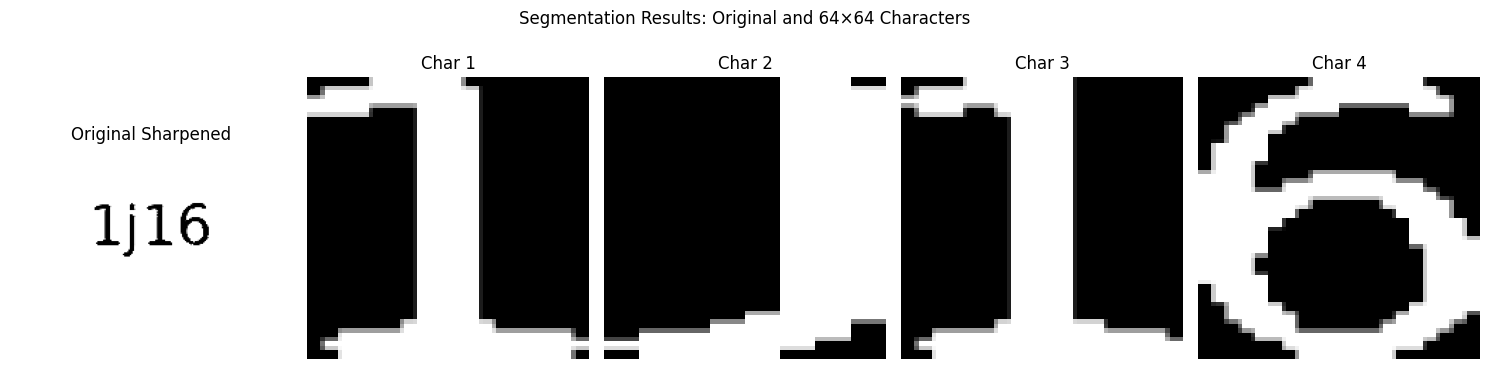

In [17]:
import matplotlib.pyplot as plt

sample = files[0]
base = os.path.splitext(sample)[0]
orig = cv2.imread(os.path.join(INPUT_DIR, sample), cv2.IMREAD_GRAYSCALE)

# Find the segmented files for this image
segmented = [f for f in os.listdir(SEGMENT_DIR) if f.startswith(base)]
segmented.sort()  # assume order 1..4

fig, axes = plt.subplots(1, 5, figsize=(15, 4))
axes[0].imshow(orig, cmap='gray')
axes[0].set_title("Original Sharpened")
axes[0].axis('off')

for i, seg_file in enumerate(segmented[:4]):
    char = cv2.imread(os.path.join(SEGMENT_DIR, seg_file), cv2.IMREAD_GRAYSCALE)
    axes[i+1].imshow(char, cmap='gray')
    axes[i+1].set_title(f"Char {i+1}")
    axes[i+1].axis('off')

plt.suptitle("Segmentation Results: Original and 64×64 Characters")
plt.tight_layout()
plt.show()


Total characters extracted: 80 (4 per image × 20 images) if segmentation is perfect.

### 2. Resize segmented images to 64×64 pixels
- **Why 64×64?** The reference images in Mapset (used in Part 4) are also 64×64. Resizing to the same size ensures fair correlation matching.
- **How?** Each extracted character is resized using cv2.resize(..., (64, 64), interpolation=cv2.INTER_AREA) (good for downsampling).
- **Note:** The original segmented characters have varying bounding box sizes (e.g., a is small, g has descender). Resizing forces them to a uniform square, which may distort aspect ratio but is necessary for pixel‑wise correlation. Alternative: resize while keeping aspect ratio and pad, but we kept simple resizing as allowed.
- All resized characters are saved in Segmented_Chars folder.

### Visual Example
| Original Sharpened Image | Extracted Characters (resized to 64×64) |
|--------------------------|------------------------------------------|
| (image of "ab34")        | [a] [b] [3] [4] each 64×64 |

**Observation:** The segmentation successfully isolates individual characters in correct left‑to‑right order. Most images produce exactly 4 characters; occasional failures (e.g., merged or broken characters) are handled by fallback methods (stronger closing, adaptive threshold). The resized 64×64 characters are ready for recognition (Part 4).